## Overview

Linear head on top of patch embeddings. This should perform the same as `LTSFLinear`—there is no non-linearity here; it is just a larger linear network.

In [1]:
import copy
import os
import math
import time

import numpy as np
import torch
from torch import nn, Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Dataset
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from typing import Literal, Tuple, Callable, NamedTuple
import pandas as pd

SEED = 2021
np.random.seed(SEED)
torch.manual_seed(SEED)

# render figures as crisp vector graphics
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
except ImportError:
    pass

device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device.")

Using cuda device.


In [2]:
class PatchPositionalEmbedding(nn.Module):
    """
    Produce 'embeddings' of patches through:
    - A linear project that maps patches in dimension `p` to dimension `d = num_hiddens`.
    - A trained lookup matrix that encodes position of `N` patches.

    Output of this layer is flattened in the (batch x channel) dimension so input into
    MultiHeadAttention is the standard (samples, sequence, embed_d) shape.
    """
    def __init__(self, num_patches: int, patch_size: int, num_hiddens: int):
        super().__init__()
        self.W_patch = nn.Linear(patch_size, num_hiddens, bias=True)

        W_position = torch.empty((num_patches, num_hiddens))
        nn.init.uniform_(W_position, -0.02, 0.02)
        self.W_position = nn.Parameter(W_position)

    def forward(self, X: Tensor):
        """
        Input: (batch * num_channels, num_patches, patch_size)
        Output: (batch * num_channels, num_patches, num_hiddens)
        """
        return self.W_patch(X) + self.W_position


class Patcher(nn.Module):
    def __init__(self, patch_size: int, stride: int):
        super().__init__()
        self.patch_size = patch_size
        self.stride = stride
        self.padding = nn.ReplicationPad1d((0, stride))

    def forward(self, X: Tensor):
        """
        Input: (batch, num_channels, lookback_size)
        Output: (batch, num_channels, num_patches, patch_size)
        """
        return self.padding(X).unfold(dimension=-1, size=self.patch_size, step=self.stride)


class LinearPatchParams(NamedTuple):
    num_channels: int  # Number of individual time series in multivariate series.
    patch_size: int=16
    stride: int=8
    lookback_size: int=512
    prediction_size: int=96
    num_hiddens: int=128
    dropout: float=0.2

    def __str__(self):
        return f"LinPatch(M={self.num_channels}, L={self.lookback_size}," \
            + f" T={self.prediction_size}, P={self.patch_size}, S={self.stride})"


class LinearPatch(nn.Module):
    def __init__(self, args: LinearPatchParams):
        super().__init__()
        self.args = args
        self.num_patches = int((args.lookback_size - args.patch_size) / args.stride) + 2

        self.patch = Patcher(args.patch_size, args.stride)
        self.embedding = PatchPositionalEmbedding(self.num_patches, args.patch_size, args.num_hiddens)
        self.dropout = nn.Dropout(args.dropout)

        self.decoder = nn.Sequential(
            nn.Flatten(start_dim=-2),
            nn.Linear(self.num_patches * args.num_hiddens, args.prediction_size))

    def forward(self, X: Tensor):
        """
        Input: (batch, num_channels, lookback_size)
        Output: (batch, num_channels, prediction_size)

        Each channel is one time series from the multivariate series.
        """
        batch, num_channels, _ = X.shape

        # (batch, num_channels, num_patches, patch_size)
        patched_X = self.patch(X)
        assert self.num_patches == patched_X.shape[2], \
            f"Expected num patches = {self.num_patches}. Actual = {patched_X.shape[2]}"

        # (batch * num_channels, num_patches, num_hiddens)
        # Batch and channels flattened together.
        X_batch_channel_flattened = patched_X.flatten(start_dim=0, end_dim=1)
        patch_embeds = self.dropout(self.embedding(X_batch_channel_flattened))

        # (batch, num_channels, num_patches, num_hiddens)
        patch_embeds = patch_embeds.unflatten(dim=0, sizes=(batch, num_channels))
        return self.decoder(patch_embeds)

In [3]:
class RandomizedChannelDataset(TensorDataset):
    """
    TensorDataset that randomly samples `channel_window_size` channels per item.

    Loading wide datasets (e.g., the traffic dataset which has 862 individual series)
    does not work with our GPU's available memory.

    The goal of this dataset is to randomly select a subset of channels for each sample
    in TRAINING. This allows our model to gradually see all channels in the dataset
    while still working within the limits of our GPU's memory by individually processing
    a subset of channels in a batch, and random sub-sampling is considerably faster
    for training.

    This dataset should ideally be used in conjunction with `TensorDataset`:
    - `RandomizedChannelDataset` speeds up training by only using `channel_window_size`
      channels per sample.
    - `TensorDataset` should be used with the validation and test sets so
      evaluation is done over all channels for all samples. Channel windowing is
      handled in the `evaluate` method to avoid overloading the GPU.
      Using a `RandomizedChannelDataset` loader for all splits can speed up
      both training and evaluation, which may be ideal for your use-case.

    Input tensors should have the shape:
        `(N_samples, num_all_channels, lookback/prediction_size)`,
    then this dataset will yield items of shape:
        `(channel_window_size, lookback/prediction_size)`.

    The entire return value is a tuple:
        `(batch_item_x, batch_item_y, random_channels)`
    A `DataLoader` stacks these return values to produce a batch triple with shape:
        batch_X:         `(batch_size, channel_window_size, lookback_size)`,
        batch_Y:         `(batch_size, channel_window_size, prediction_size)`,
        random_channels: `(batch_size, random_channels)`,


    IMPORTANT: This dataset may ONLY be used if `affine=False` in the RevIN layer, or
    PatchTST's `num_channels` is set to match `channel_window_size`.
    """
    DEFAULT_CHANNEL_WINDOW_SIZE = 10

    def __init__(
            self,
            *tensors: Tensor,
            channel_window_size: int = DEFAULT_CHANNEL_WINDOW_SIZE
    ) -> None:
        super().__init__(*tensors)
        self.num_all_channels = self.tensors[0].shape[1]
        self.channel_window_size = min(channel_window_size, self.num_all_channels)

    def __getitem__(self, index):
        # X[index] shape (num_channels, lookback_size)
        # Y[index] shape (num_channels, prediction_size)
        # where num_channels is all the channels.
        #
        # Randomly select self.channel_window_size channels to return
        # tensors of size (N, channel_window_size, window_size)
        random_channels = torch.randperm(self.num_all_channels)[:self.channel_window_size]
        return *tuple(tensor[index, random_channels] for tensor in self.tensors), random_channels


def load_time_series_data(
    file_path: str,
    delimiter: str = ",",
) -> np.ndarray:
    """
    Load raw multivariate time-series data into a 2D float tensor of shape (T, num_channels).

    The file is expected to be a text file with no header row or index (time) column. I.e., it
    should directly be raw data rows. Each row must record a timestamp, and each column a channel
    of the multivariate series.
    """
    arr = np.loadtxt(file_path, delimiter=delimiter)
    if arr.ndim != 2:
        raise ValueError(f"Expected 2D tensor of shape (T, num_channels), got shape {arr.shape}")

    return arr


def to_data_loader(data: Dataset, batch_size: int, collate_fn=None, shuffle=False, seed=SEED) -> DataLoader:
    g = torch.Generator()
    g.manual_seed(seed)

    return DataLoader(
        data,
        batch_size,
        shuffle=shuffle,
        collate_fn=collate_fn,
        generator=g)


def split_time_series_data(
    raw_data: np.ndarray,
    lookback_size: int,
    prediction_size: int,
    split_ratios: Tuple[float, float, float] = (0.7, 0.1, 0.2),
    batch_size: int = 24,
    dtype: torch.dtype = torch.float32,
) -> Tuple[
    DataLoader[RandomizedChannelDataset],
    DataLoader[TensorDataset],
    DataLoader[TensorDataset],
    StandardScaler
]:
    """
    Construct a PyTorch TensorDataset containing (X, Y) sliding-window pairs. Each window pair
    logically consists of X_i = [...lookback_size...] historic time steps used to predict
    Y_i = [...prediction_size...] events into the future, for each channel.

    In other words,
        X[i] = data[i : i + lookback_size]^T    shape: (num_channels, lookback_size)
        Y[i] = data[i + lookback_size : i + lookback_size + prediction_size]^T
                                                shape: (num_channels, prediction_size)
    Returns:
       train/val/test: `DataLoader`s, containing `TensorDataset`s that have:
                tensors[0] (X): shape (N, num_channels, lookback_size)
                tensors[1] (Y): shape (N, num_channels, prediction_size)
            where N is the number of valid sliding windows. Data is standardized.

        scaler: the `StandardScaler` used to standardize the data, in order to
            reverse the process for plotting in the original scale of the data.
    """
    scaler = StandardScaler()
    has_fit = False
    def lookback_and_prediction_windows(split: np.ndarray) -> Dataset:
        nonlocal scaler, has_fit
        split = scaler.transform(split) if has_fit else scaler.fit_transform(split)

        # Stride of 1: heavily overlap samples.
        # Unfolding yields the shape (N_samples, channels, window_size)
        tensor = torch.from_numpy(split).to(dtype=dtype)
        X = tensor.unfold(dimension=0, size=lookback_size, step=1)
        Y = tensor[lookback_size:].unfold(dimension=0, size=prediction_size, step=1)

        num_samples = min(X.shape[0], Y.shape[0])
        if has_fit:
            dataset = TensorDataset(X[:num_samples], Y[:num_samples])
        else:
            dataset = RandomizedChannelDataset(X[:num_samples], Y[:num_samples])

        has_fit = True

        return dataset

    num_timesteps, _ = raw_data.shape

    train_ratio, val_ratio, _ = split_ratios
    train_size = int(num_timesteps * train_ratio)
    val_size = int(num_timesteps * val_ratio)
    test_size = num_timesteps - train_size - val_size

    # Pull lookback windows in val/test from the split before it (predicted values
    # in val/test are never seen from another split).
    # This matches the offical code's implementation.
    train_dataset, val_dataset, test_dataset = map(lookback_and_prediction_windows, [
        raw_data[:train_size],
        raw_data[train_size - lookback_size:train_size + val_size],
        raw_data[num_timesteps - test_size - lookback_size:],
    ])

    return to_data_loader(train_dataset, batch_size, shuffle=True), \
            to_data_loader(val_dataset, batch_size), \
            to_data_loader(test_dataset, batch_size), \
            scaler

In [4]:
def check_cuda_memory():
    allocated = torch.cuda.memory_allocated() / (1024 ** 3)
    reserved = torch.cuda.memory_reserved() / (1024 ** 3)
    peak = torch.cuda.max_memory_allocated() / (1024 ** 3)

    print(f"Allocated: {allocated:.2f} GB | Reserved: {reserved:.2f} GB | Peak: {peak:.2f} GB")


def train_epoch(
        model: nn.Module,
        train_loader: DataLoader,
        loss_fn,
        optimizer) -> float:
    model.train()
    total_loss = 0.0   # sum of per-example losses
    total_examples = 0
    for batch in train_loader:
        X, y = batch[0], batch[1]  # Work with TensorDataset or RandomizedChannelDataset

        # Typical training workflow: Dataset/loader are on the CPU.
        # Just load one batch to the GPU.
        X, y = X.to(device), y.to(device)
        y_pred = model(X)
        loss = loss_fn(y_pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # scheduler.step()

        # loss_fn returns the mean over the batch, so multiply back out by the
        # batch size to accumulate an exact, example-weighted average (the final
        # batch is smaller, so a plain mean of batch means would be biased).
        total_loss += loss.item() * y.numel()
        total_examples += y.numel()

    return total_loss / total_examples


def evaluate(
        model: nn.Module,
        data_loader: DataLoader[TensorDataset],
        loss_fn: nn.Module,
        channel_chunk_size=96) -> float:
    # channel_chunk_size: Take small windows of channels to avoid running out of memory
    # on the GPU. This works with a validation/test dataloader that does not do any
    # windowing of channels (a plain TensorDataset), or one that is already windowing
    # RandomizedChannelDataset (in which case splitting here may only yield one item).
    model.eval()
    total_loss = 0.0
    count = 0
    with torch.no_grad():
        for batch in data_loader:  # (batch_size, channels, time_window_size)
            X, y = batch[0], batch[1]  # Work with TensorDataset or RandomizedChannelDataset

            for Xc, yc in zip(X.split(channel_chunk_size, dim=1), y.split(channel_chunk_size, dim=1)):
                Xc, yc = Xc.to(device), yc.to(device)
                total_loss += loss_fn(model(Xc), yc).item() * yc.numel()
                count += yc.numel()
    return total_loss / count


def train_early_stopping(
        model: nn.Module,
        train_loader,
        valid_loader,
        loss_fn,
        optimizer,
        epochs,
        verbosity: Literal[0]|Literal[1]|Literal[2] = 0
) -> tuple[list[float], list[float]]:
    best_val_loss = float('inf')
    patience_counter = 0
    patience = 10          # number of epochs to wait for an improvement
    best_state = None

    train_losses, valid_losses = [], []
    for epoch in range(epochs):
        start = time.time()
        train_loss = train_epoch(model, train_loader, loss_fn, optimizer)
        if verbosity > 1:
            print(f'  train time {time.time() - start:.0f}s')

        eval_start = time.time()
        val_loss = evaluate(model, valid_loader, loss_fn)
        if verbosity > 1:
            print(f'  eval time {time.time() - eval_start:.0f}s')

        if verbosity > 0:
            print(f'epoch {epoch + 1:2d}  train loss {train_loss:.3f}  '
                f'val loss {val_loss:.3f}  '
                f'({time.time() - start:.0f}s)')
            if epoch % 5 == 0 and verbosity > 1:
                check_cuda_memory()

        train_losses.append(train_loss)
        valid_losses.append(val_loss)

        if val_loss < best_val_loss:
            # still improving: remember this model as the best so far
            best_val_loss = val_loss
            patience_counter = 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            # not better than our current best.  keep training for a few more epochs
            # to give it a chance to improve (that is what `patience` controls)
            patience_counter += 1
            if patience_counter >= patience:
                break

    # Restore the best weights before evaluating. Large LRs will fail
    # to produce a validation loss < best_val_loss. Don't restore to
    # anything in this case.
    if best_state:
        model.load_state_dict(best_state)

    return train_losses, valid_losses


def plot_loss(
    train_losses: list[float],
    val_losses: list[float],
    title: str = ""
):
    epochs_axis = range(1, len(train_losses) + 1)
    _, ax_loss = plt.subplots(figsize=(4, 2.4))

    l1 = ax_loss.plot(epochs_axis, train_losses, label='training loss')
    l2 = ax_loss.plot(epochs_axis, val_losses, label='validation loss')
    ax_loss.set_xlabel('epoch')
    ax_loss.set_ylabel('loss')

    lines = l1 + l2
    ax_loss.legend(lines, [ln.get_label() for ln in lines], bbox_to_anchor=(1.3, 1), loc='upper left')
    plt.title(title)


class ExperimentRunner:
    """
    A class that facilitates experimenting with different model configurations.
    Each added experiment gets `n` models trained with a different random seed (`n = 5`).
    Averaged results are returned in a dataframe after evaluating the models against
    the validation set. Plotting some/all of the experiments is also possible.
    """
    REPORT_COLUMNS = ["Classifier", "Loss (val)", "Epochs", "Param count"]

    # Results used in plots, saved in case we want to recall results from this
    # runner without re-running all experiments.
    class ExpResults(NamedTuple):
        params: NamedTuple
        model: nn.Module
        train_losses: list[float]
        val_losses: list[float]

    def __init__(self, model_constr: Callable[[NamedTuple], nn.Module]):
        self.model_constr = model_constr

        # Subclass used for hyperparams. E.g., TDNNHyperParams. Model must be
        # constructable by running model_constr(experiment_params).
        self.experiments: list[NamedTuple] = []
        self.experiments_to_plot: set[str] = set()
        self.experiment_results: list[ExperimentRunner.ExpResults] = []

        self.epochs: int = -1
        self.lr: float = 0.0001
        self.train_loader = None
        self.val_loader = None

    def with_epochs(self, epochs: int) -> ExperimentRunner:
        self.epochs = epochs
        return self

    def with_lr(self, lr: float) -> ExperimentRunner:
        self.lr = lr
        return self

    def with_data(self, train_loader: DataLoader, val_loader: DataLoader) -> ExperimentRunner:
        self.train_loader = train_loader
        self.val_loader = val_loader
        return self

    def add_experiments(self, *params) -> ExperimentRunner:
        self.experiments.extend(params)
        return self

    def and_plot(self, *params) -> ExperimentRunner:
        """Plot a given set of hyper params. These must match planned experiments."""
        self.experiments_to_plot.update(map(str, params))
        return self

    def with_plots(self) -> ExperimentRunner:
        """Plot all experiments recorded thus far when this runner is executed."""
        self.experiments_to_plot.update(map(str, self.experiments))
        return self

    def get_results(self) -> list[ExperimentRunner.ExpResults]:
        return self.experiment_results.copy()

    def run(self, verbosity: Literal[0]|Literal[1]|Literal[2] = 0) -> pd.DataFrame:
        run_data = []
        for params in self.experiments:
            plot_name = None
            serialized_params = str(params)
            print(f"Running experiment: {params}")

            if serialized_params in self.experiments_to_plot:
                plot_name = serialized_params

            model = self.model_constr(params).to(device)
            optimizer = torch.optim.Adam(model.parameters(), lr=self.lr)
            # scheduler = torch.optim.lr_scheduler.OneCycleLR(
            #     optimizer,
            #     pct_start=0.2,
            #     max_lr=self.lr,
            #     epochs=self.epochs,
            #     steps_per_epoch=len(self.train_loader))
            loss_fn = nn.MSELoss()

            train_losses, val_losses = train_early_stopping(
                model,
                self.train_loader,
                self.val_loader,
                loss_fn=loss_fn,
                optimizer=optimizer,
                epochs=self.epochs,
                verbosity=verbosity)
            self.experiment_results.append(ExperimentRunner.ExpResults(
                params=params,
                model=model.cpu(),
                train_losses=train_losses,
                val_losses=val_losses))
            if plot_name:
                plot_loss(
                    train_losses=train_losses,
                    val_losses=val_losses,
                    title=plot_name,
                )

            param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
            actual_epochs = len(train_losses)
            run_data.append([serialized_params, min(val_losses), actual_epochs, param_count])

        df = pd.DataFrame(
            run_data,
            columns=self.REPORT_COLUMNS
        )
        return df.round(4).astype(object).fillna("Diverged")


In [5]:
# NOTE: This only works with TensorDataset.
# `show_prediction_from_randomized_channel_set` works with RandomizedChannelDataset.
def show_random_prediction(
        models: list[nn.Module],
        loader: DataLoader[TensorDataset],
        scaler: StandardScaler,
        channel_labels: list[str] = []):
    # Grab the first sample from the first batch, channel 0.
    # When using the val loader, this sample starts on line 11,769 of
    # the full dataset.
    # The scaler expects items in the shape (time, num_channels).
    random_time = np.random.randint(0, len(loader.dataset))
    X, Y = loader.dataset[random_time]  # (channels, lookback/pred_size)
    channel = np.random.randint(0, len(X))
    sample = Tensor(scaler.inverse_transform(X.T).T[channel])
    truth = Tensor(scaler.inverse_transform(Y.T).T[channel])

    _, ax = plt.subplots(figsize=(10, 4))

    prediction_xticks = np.arange(len(sample), len(sample) + len(truth))
    l1 = ax.plot(sample, label='lookback window')
    l2 = ax.plot(prediction_xticks, truth,
                label='true future series')

    lines = l1 + l2
    for model in models:
        with torch.no_grad():
            single_sample_batch = X.unsqueeze(0)
            model = model.to(device)
            model.eval()
            all_preds = model(single_sample_batch.to(device)).cpu()
            preds = scaler.inverse_transform(all_preds[0].T).T[channel]

        # print("lookback window, future truth, future prediction",
        #     sample.shape, truth.shape, preds.shape)

        line = ax.plot(prediction_xticks, preds,
                    label='predicted future series')
        lines += line

    if channel_labels:
        plt.title(channel_labels[channel])
    ax.legend(lines, [ln.get_label() for ln in lines], bbox_to_anchor=(1.05, 1), loc='upper left');


### $L=512$, $T=96$

- `PatchTST` loss = 0.317, but 70s per epoch (97 total)
- `LinearPatch` loss = 0.3298. Fast.
- `Linear` loss = 0.3285

In [75]:
all_traffic_data = load_time_series_data("./data/traffic.txt", delimiter=",")
traffic_train_loader, traffic_val_loader, _, traffic_scaler = split_time_series_data(
    all_traffic_data,
    lookback_size=512,
    prediction_size=96,
    batch_size=64)

example_batch_X, example_batch_Y, _ = next(iter(traffic_train_loader))
print(f"batch_X shape: {example_batch_X.shape}")
print(f"batch_y shape: {example_batch_Y.shape}")

batch_X shape: torch.Size([64, 10, 512])
batch_y shape: torch.Size([64, 10, 96])


Running experiment: LinPatch(M=862, L=512, T=96, P=16, S=8)
epoch  1  train loss 0.335  val loss 0.342  (3s)
epoch  2  train loss 0.267  val loss 0.335  (3s)
epoch  3  train loss 0.260  val loss 0.333  (3s)
epoch  4  train loss 0.255  val loss 0.332  (3s)
epoch  5  train loss 0.250  val loss 0.331  (3s)
epoch  6  train loss 0.248  val loss 0.330  (3s)
epoch  7  train loss 0.246  val loss 0.332  (3s)
epoch  8  train loss 0.245  val loss 0.331  (3s)
epoch  9  train loss 0.242  val loss 0.331  (3s)
epoch 10  train loss 0.245  val loss 0.330  (3s)
epoch 11  train loss 0.245  val loss 0.331  (3s)
epoch 12  train loss 0.243  val loss 0.332  (3s)
epoch 13  train loss 0.242  val loss 0.331  (3s)
epoch 14  train loss 0.242  val loss 0.332  (3s)
epoch 15  train loss 0.242  val loss 0.331  (3s)
epoch 16  train loss 0.240  val loss 0.331  (3s)
epoch 17  train loss 0.241  val loss 0.331  (3s)
epoch 18  train loss 0.242  val loss 0.330  (3s)
epoch 19  train loss 0.242  val loss 0.330  (3s)
epoch 20 

,Classifier,Loss (val),Epochs,Param count
0,"LinPatch(M=862, L=512, T=96, P=16, S=8)",0.3298,39,796896


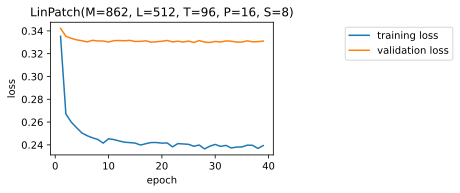

In [76]:
runner1_1 = (
    ExperimentRunner(LinearPatch)
        .with_epochs(100)
        .with_data(traffic_train_loader, traffic_val_loader)
        .add_experiments(
            LinearPatchParams(
                num_channels=all_traffic_data.shape[1],
                lookback_size=512,
                prediction_size=96,
            )
        ).with_plots()
)

runner_results1_1 = runner1_1.run(verbosity=1)
runner_results1_1

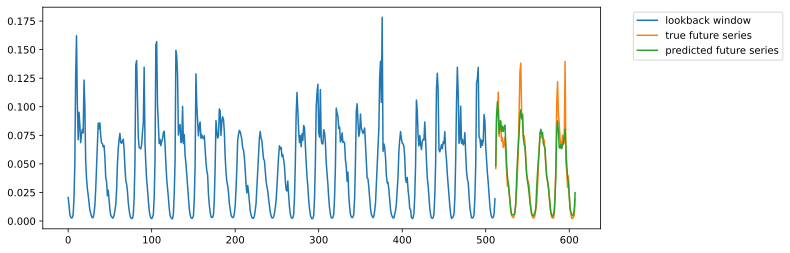

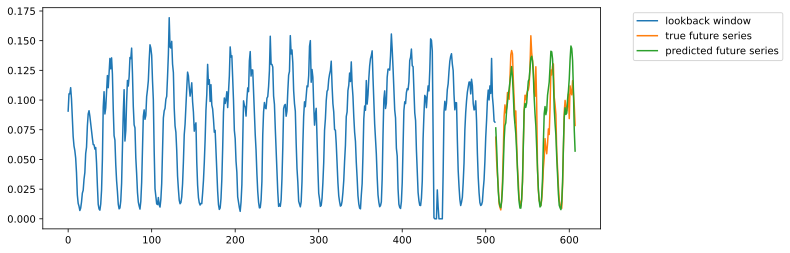

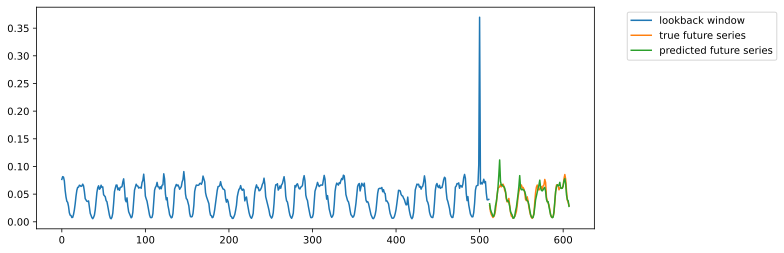

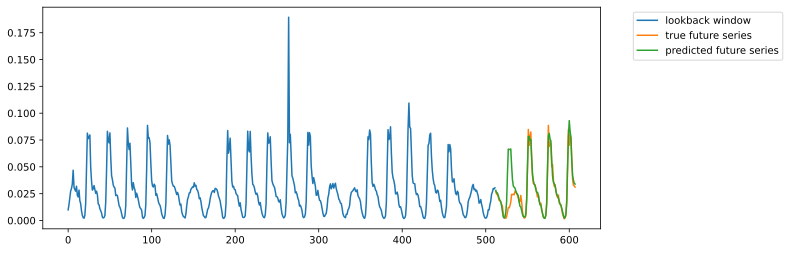

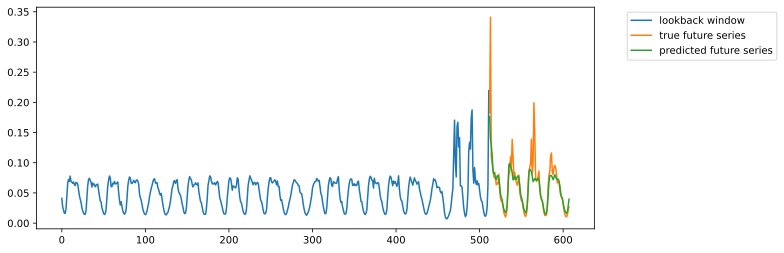

In [81]:
for _ in range(5):
    show_random_prediction(
        list(map(lambda x: x.model, runner1_1.get_results())),
        traffic_val_loader,
        traffic_scaler)

## $L= 336$, $T = 192$

batch_X shape: torch.Size([64, 10, 336])
batch_y shape: torch.Size([64, 10, 192])
Running experiment: LinPatch(M=862, L=336, T=192, P=16, S=8)
epoch  1  train loss 0.357  val loss 0.360  (3s)
epoch  2  train loss 0.282  val loss 0.353  (2s)
epoch  3  train loss 0.274  val loss 0.349  (2s)
epoch  4  train loss 0.268  val loss 0.350  (2s)
epoch  5  train loss 0.268  val loss 0.348  (2s)
epoch  6  train loss 0.262  val loss 0.347  (2s)
epoch  7  train loss 0.261  val loss 0.348  (2s)
epoch  8  train loss 0.262  val loss 0.347  (2s)
epoch  9  train loss 0.258  val loss 0.346  (2s)
epoch 10  train loss 0.258  val loss 0.346  (2s)
epoch 11  train loss 0.258  val loss 0.348  (2s)
epoch 12  train loss 0.257  val loss 0.347  (2s)
epoch 13  train loss 0.258  val loss 0.346  (2s)
epoch 14  train loss 0.257  val loss 0.346  (2s)
epoch 15  train loss 0.258  val loss 0.347  (2s)
epoch 16  train loss 0.257  val loss 0.347  (2s)
epoch 17  train loss 0.259  val loss 0.346  (2s)
epoch 18  train loss 0.2

,Classifier,Loss (val),Epochs,Param count
0,"LinPatch(M=862, L=336, T=192, P=16, S=8)",0.3456,20,1039936


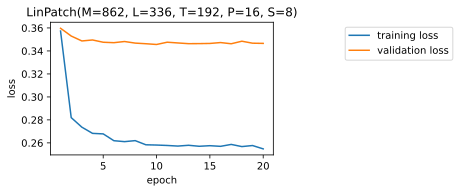

In [7]:
all_traffic_data = load_time_series_data("./data/traffic.txt", delimiter=",")
traffic_train_loader, traffic_val_loader, _, traffic_scaler = split_time_series_data(
    all_traffic_data,
    lookback_size=336,
    prediction_size=192,
    batch_size=64)

example_batch_X, example_batch_Y, _ = next(iter(traffic_train_loader))
print(f"batch_X shape: {example_batch_X.shape}")
print(f"batch_y shape: {example_batch_Y.shape}")

runner1_2 = (
    ExperimentRunner(LinearPatch)
        .with_epochs(100)
        .with_data(traffic_train_loader, traffic_val_loader)
        .add_experiments(
            LinearPatchParams(
                num_channels=all_traffic_data.shape[1],
                lookback_size=336,
                prediction_size=192,
            )
        ).with_plots()
)

runner_results1_2 = runner1_2.run(verbosity=1)
runner_results1_2

## $L=512$, $P=720$

batch_X shape: torch.Size([64, 10, 512])
batch_y shape: torch.Size([64, 10, 720])
Running experiment: LinPatch(M=862, L=512, T=720, P=16, S=8)
epoch  1  train loss 0.360  val loss 0.410  (4s)
epoch  2  train loss 0.300  val loss 0.401  (4s)
epoch  3  train loss 0.292  val loss 0.400  (4s)
epoch  4  train loss 0.288  val loss 0.399  (4s)
epoch  5  train loss 0.284  val loss 0.398  (4s)
epoch  6  train loss 0.283  val loss 0.397  (4s)
epoch  7  train loss 0.282  val loss 0.398  (4s)
epoch  8  train loss 0.280  val loss 0.398  (4s)
epoch  9  train loss 0.278  val loss 0.398  (4s)
epoch 10  train loss 0.277  val loss 0.399  (4s)
epoch 11  train loss 0.278  val loss 0.397  (4s)
epoch 12  train loss 0.276  val loss 0.398  (4s)
epoch 13  train loss 0.278  val loss 0.397  (4s)
epoch 14  train loss 0.277  val loss 0.397  (4s)
epoch 15  train loss 0.276  val loss 0.397  (4s)
epoch 16  train loss 0.274  val loss 0.398  (4s)
epoch 17  train loss 0.275  val loss 0.398  (4s)
epoch 18  train loss 0.2

,Classifier,Loss (val),Epochs,Param count
0,"LinPatch(M=862, L=512, T=720, P=16, S=8)",0.3959,31,5909328


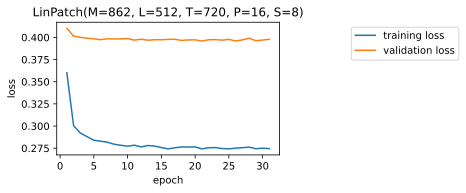

In [8]:
all_traffic_data = load_time_series_data("./data/traffic.txt", delimiter=",")
traffic_train_loader, traffic_val_loader, _, traffic_scaler = split_time_series_data(
    all_traffic_data,
    lookback_size=512,
    prediction_size=720,
    batch_size=64)

example_batch_X, example_batch_Y, _ = next(iter(traffic_train_loader))
print(f"batch_X shape: {example_batch_X.shape}")
print(f"batch_y shape: {example_batch_Y.shape}")

runner1_3 = (
    ExperimentRunner(LinearPatch)
        .with_epochs(100)
        .with_data(traffic_train_loader, traffic_val_loader)
        .add_experiments(
            LinearPatchParams(
                num_channels=all_traffic_data.shape[1],
                lookback_size=512,
                prediction_size=720,
            )
        ).with_plots()
)

runner_results1_3 = runner1_3.run(verbosity=1)
runner_results1_3

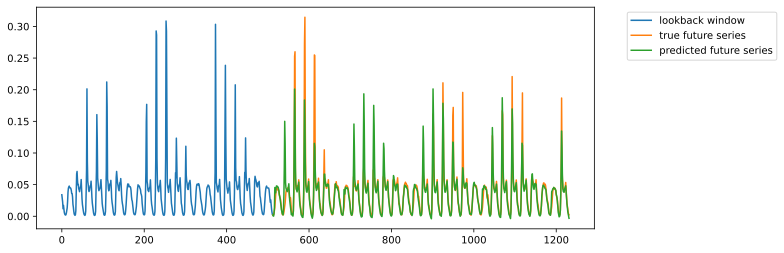

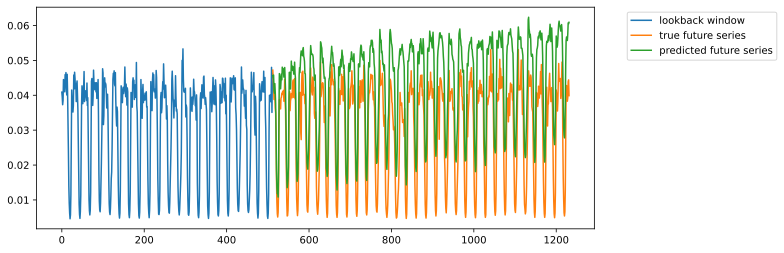

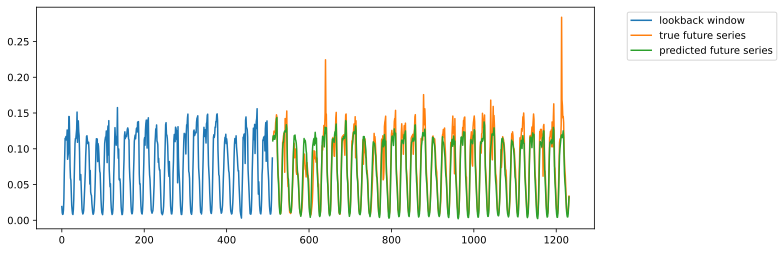

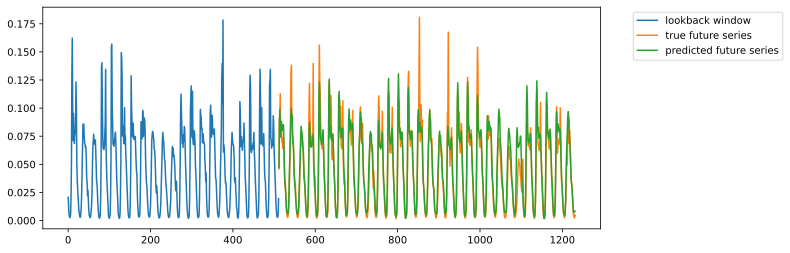

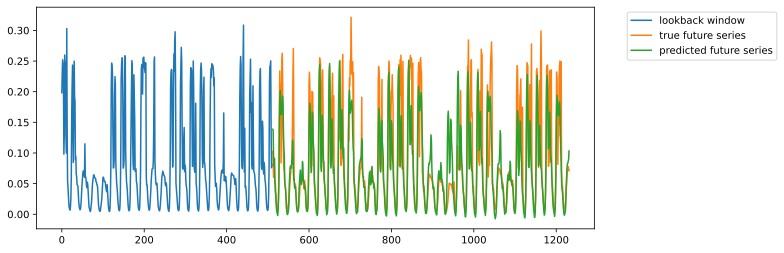

In [9]:
for _ in range(5):
    show_random_prediction(
        list(map(lambda x: x.model, runner1_3.get_results())),
        traffic_val_loader,
        traffic_scaler)